# Chunking long documents: Decisions API vs classic splitters

**Question.** Can OpenAI's Decisions API (`openai/gpt-6-luna-decisions` via OpenRouter's alpha endpoint) decide
*where* to split a long document better than the usual chunkers? It returns calibrated yes/no probabilities
(`noul` questions), so we can ask, for every paragraph, *"does a new section or topic start here?"*. Then we
pick the chunk boundaries with a small dynamic program under a token budget.

**Why it matters.** Chunk boundaries decide what a RAG system can cite. A chunk that glues the end of one section to the start of the next is hard to retrieve and confusing to quote. Classic splitters cut by length; this tests whether a cheap probabilistic judgement of "a new section starts here" does better.

**Data: real, complex public documents**, taken from the RAG benchmark of the public
[lumen-copilot](https://github.com/k-sandhu/lumen-copilot) repo (`backend/tests/eval/benchmark`):
an ML paper, a NIST standard, an IETF RFC, a shareholder letter, an IPCC report and the IRS 1040 instructions.
They are evaluated against the benchmark's human-written questions and **verbatim evidence quotes**.

**Chunkers compared** (same budget: chunks of at most 400 tokens)
| Method | How it splits |
|---|---|
| Fixed tokens | 400-token windows, 50-token overlap |
| Recursive | split on paragraphs → sentences → words, then pack up to 400 tokens |
| Headings + DP | heading heuristic scores each paragraph; DP picks the cuts |
| Semantic + DP | embedding distance between neighbouring paragraphs scores each candidate |
| **Decisions + DP** | Decisions API P(new section starts here) scores each candidate |

The last three share the **same candidate positions and the same DP segmenter**. Only the boundary score
differs, so their comparison is apples to apples.

**Evaluation.** (1) Does a scorer find the real section starts (from the PDF outline / RFC numbering)?
(2) Do chunks respect sections? (3) Does retrieval over the chunks find the benchmark's evidence passages?

**Headline result.** As a section-start detector the Decisions API scores mean AP 0.60 (ROC-AUC 0.88) against 0.43 for a heading heuristic and 0.32 for embedding distance. Its chunks hit 85% of real section starts and only 8% mix two sections (fixed windows: 28% and 46%), for about $0.37 per million document tokens. Retrieval recall@5 is the same for every chunker (0.76-0.79) on this small question set.

## Contents
1. [Setup](#1.-Setup)
2. [Data](#2.-Data)
3. [Chunkers](#3.-Chunkers)
4. [Build all chunkings](#4.-Build-all-chunkings)
5. [Evaluation](#5.-Evaluation)
6. [Takeaways](#6.-Takeaways)

## Workflow
The whole experiment from data to results, with the counts from this run. Every model response is cached in `data/`, so a re-run replays it without API calls.

```mermaid
flowchart TD
    docs["6 public documents: 5 PDFs + the RFC 9110 text<br/>386,257 tokens"]
    qs["lumen-copilot benchmark questions.csv<br/>33 question and evidence-quote pairs"]
    ext["Extract text blocks (PyMuPDF)<br/>9,096 blocks, 716 gold section starts<br/>from PDF outlines and RFC numbering"]
    loc["Locate each evidence quote<br/>33 of 33 found"]
    units["Candidate units<br/>blocks merged to ≥ 40 tokens, split above 200<br/>4,534 units"]
    base["Fixed tokens, Recursive<br/>no model"]
    head["Headings scorer<br/>regex, no model"]
    sem["Semantic scorer<br/>free embedding model, 1 vector per unit"]
    dec["Decisions scorer<br/>144 Decisions calls, 1.44M input tokens, $0.14"]
    dp["Shared DP segmenter<br/>chunks ≤ 400 tokens"]
    chunks["5 chunkings<br/>1,104 to 1,487 chunks each"]
    ev1["Boundary detection<br/>AP and ROC-AUC on 4 outlined documents"]
    ev2["Section structure<br/>section-start recall, mixed-section chunks"]
    ev3["Retrieval over a pooled embedding index<br/>recall@1, 3, 5 and MRR on 33 quotes"]
    res["Decisions + DP: AP 0.60, 85% of section starts hit, 8% mixed chunks<br/>recall@5 0.76-0.79 for every chunker"]
    docs --> ext
    ext --> units
    ext --> base --> chunks
    qs --> loc
    ext --> loc
    units --> head --> dp
    units --> sem --> dp
    units --> dec --> dp
    dp --> chunks
    head --> ev1
    sem --> ev1
    dec --> ev1
    chunks --> ev2
    chunks --> ev3
    loc --> ev3
    ev1 --> res
    ev2 --> res
    ev3 --> res
```

## 1. Setup
Runs offline: every API response is cached in `data/`, so a re-run replays from disk and needs no key. `OPENROUTER_API_KEY` is needed only for calls that are not cached. Dependencies are in `requirements.txt` at the repo root.
Embeddings use the **free** `nvidia/llama-nemotron-embed-vl-1b-v2:free` model ($0, 1,000 free requests/day per
key). Free endpoints may log inputs, which is fine for these public documents but never for private data. The
Decisions endpoint has no free variant; its spend is tracked at the end of the notebook.

In [1]:
import csv, hashlib, json, os, re, shutil, threading, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import requests
import tiktoken
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd()  # this notebook's folder
DATA = ROOT / "data"
(DATA / "docs").mkdir(parents=True, exist_ok=True)

DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
DECISIONS_MODEL = "openai/gpt-6-luna-decisions"
EMBED_MODEL = "nvidia/llama-nemotron-embed-vl-1b-v2:free"  # free
MAX_CHUNK, MIN_CHUNK = 400, 100   # token budget shared by every chunker
MIN_UNIT, MAX_UNIT = 40, 200      # candidate "paragraph" units for the boundary scorers
WORKERS = 8

HEADERS = {"Authorization": f"Bearer {os.environ.get('OPENROUTER_API_KEY', '')}"}  # only used on a cache miss
enc = tiktoken.get_encoding("o200k_base")
ntok = lambda s: len(enc.encode(s, disallowed_special=()))
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### 1.1 Helpers
`post()` retries HTTP 429 and 5xx responses with backoff and raises `Refused` when the model declines to answer.
`JsonlCache` stores each Decisions response under a hash of the full request (`data/decisions_cache.jsonl`), so a
re-run makes no calls. `decide()` makes one Decisions call and `embed()` returns cached, normalised 512-dimension
embeddings (`data/embeddings_cache.npz`).

In [2]:
class Refused(Exception):
    """The model declined to answer (HTTP 502 'refused to answer'); not worth retrying."""


def post(url, payload, tries=8):
    """POST with exponential backoff on 429/5xx; raises on any other error."""
    if not os.environ.get("OPENROUTER_API_KEY"):
        raise RuntimeError(f"Not in the cache and OPENROUTER_API_KEY is not set ({url})")
    for attempt in range(tries):
        r = requests.post(url, json=payload, headers=HEADERS, timeout=180)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 502 and "refused" in r.text:
            raise Refused(r.text[:200])
        if r.status_code in (429, 500, 502, 503, 504) and attempt < tries - 1:
            time.sleep(min(60, 5 * 2**attempt) if r.status_code == 429 else 2**attempt)  # free models rate-limit harder
            continue
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:400]}")


class JsonlCache:
    """Append-only on-disk cache for API responses, keyed by the request payload."""

    def __init__(self, path):
        self.path, self.lock, self.data = path, threading.Lock(), {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.data[row["key"]] = row["value"]

    def get(self, payload, fn):
        key = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
        if key not in self.data:
            value = fn(payload)
            with self.lock:
                self.data[key] = value
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(json.dumps({"key": key, "value": value}) + "\n")
        return self.data[key]


decision_cache = JsonlCache(DATA / "decisions_cache.jsonl")


def decide(state, questions):
    """One Decisions API call. Returns {'answers', 'usage', 'latency_s'}; raises Refused."""

    def call(payload):
        t0 = time.perf_counter()
        try:
            out = post(DECISIONS_URL, payload)
        except Refused as e:
            return {"refused": str(e)}
        return {"answers": out["answers"], "usage": out["usage"], "latency_s": time.perf_counter() - t0}

    result = decision_cache.get({"model": DECISIONS_MODEL, "state": state, "questions": questions}, call)
    if "refused" in result:
        raise Refused(result["refused"])
    return result


EMB_PATH = DATA / "embeddings_cache.npz"
if EMB_PATH.exists():
    with np.load(EMB_PATH) as z:  # plain arrays, no pickle
        emb_cache = dict(zip(z["keys"].tolist(), z["vectors"]))
else:
    emb_cache = {}


def save_emb_cache():
    keys = list(emb_cache)
    np.savez(EMB_PATH, keys=np.array(keys), vectors=np.stack([emb_cache[k] for k in keys]).astype(np.float32))


def embed(texts, batch=256):
    """L2-normalised embeddings (512-d), cached per text."""
    key = lambda t: hashlib.sha1(f"{EMBED_MODEL}|{t}".encode()).hexdigest()
    missing = list(dict.fromkeys(t for t in texts if key(t) not in emb_cache))
    for i in range(0, len(missing), batch):
        part = missing[i : i + batch]
        inputs = [t if t.strip() else "(blank)" for t in part]  # the free model rejects empty strings
        out = post(EMBED_URL, {"model": EMBED_MODEL, "input": inputs, "dimensions": 512, "encoding_format": "float"})
        for t, d in zip(part, sorted(out["data"], key=lambda d: d["index"])):
            emb_cache[key(t)] = np.asarray(d["embedding"], dtype=np.float32)
    if missing:
        save_emb_cache()
    X = np.stack([emb_cache[key(t)] for t in texts])
    return X / np.linalg.norm(X, axis=1, keepdims=True)

## 2. Data
The six documents are downloaded from their publishers on the first run (URLs in the next cell) into
`data/docs/`, which is git-ignored. The questions and evidence quotes come from the benchmark's
`questions.csv`, kept in `data/` (and downloaded from the lumen-copilot repo if missing).

In [3]:
DOCS = {  # file_id → (url, title)
    "arxiv-attention": ("https://arxiv.org/pdf/1706.03762v7", "Attention Is All You Need (arXiv)"),
    "nist-sp-800-63b": ("https://nvlpubs.nist.gov/nistpubs/SpecialPublications/NIST.SP.800-63b.pdf", "NIST SP 800-63B Digital Identity Guidelines"),
    "rfc9110-http-semantics": ("https://www.rfc-editor.org/rfc/rfc9110.txt", "RFC 9110: HTTP Semantics"),
    "berkshire-2023-letter": ("https://www.berkshirehathaway.com/letters/2023ltr.pdf", "Berkshire Hathaway 2023 Shareholder Letter"),
    "ipcc-ar6-wg1-spm": ("https://www.ipcc.ch/report/ar6/wg1/downloads/report/IPCC_AR6_WGI_SPM.pdf", "IPCC AR6 WG1 Summary for Policymakers"),
    "irs-1040-instructions-2024": ("https://www.irs.gov/pub/irs-prior/i1040gi--2024.pdf", "IRS Form 1040 Instructions (2024)"),
}
for fid, (url, _) in DOCS.items():
    path = DATA / "docs" / (fid + (".txt" if url.endswith(".txt") else ".pdf"))
    if not path.exists():
        r = requests.get(url, headers={"User-Agent": "experiment-notebooks/0.1 (research)"}, timeout=180)
        r.raise_for_status()
        path.write_bytes(r.content)

QUESTIONS_URL = "https://raw.githubusercontent.com/k-sandhu/lumen-copilot/main/backend/tests/eval/benchmark/questions.csv"
q_path = DATA / "questions.csv"
if not q_path.exists():
    r = requests.get(QUESTIONS_URL, timeout=60)  # public benchmark file
    r.raise_for_status()
    q_path.write_bytes(r.content)
questions = pd.read_csv(q_path, encoding="utf-8-sig").fillna("")
evidence = pd.DataFrame([{"qid": q["qid"], "question": q["question"], "doc": q[f"evidence{k}_file"], "quote": q[f"evidence{k}_quote"]}
                         for q in questions.to_dict("records") if q["answerable"] == "yes" for k in (1, 2)
                         if q[f"evidence{k}_file"] in DOCS])
print(f"{len(evidence)} (question, evidence quote) pairs over {evidence.doc.nunique()} documents")
evidence.head(3)

33 (question, evidence quote) pairs over 6 documents


,qid,question,doc,quote
0,bm-015,"According to RFC 9110, what does the 405 status code indicate?",rfc9110-http-semantics,The 405 (Method Not Allowed) status code indicates that the method\n received in the request-l...
1,bm-016,Which header field must an origin server generate in a 405 (Method Not Allowed) response?,rfc9110-http-semantics,An origin server MUST generate an Allow\n header field in a 405 (Method Not Allowed) response ...
2,bm-017,Which request methods does RFC 9110 define to be safe?,rfc9110-http-semantics,"Of the request methods defined by this specification, the GET, HEAD,\n OPTIONS, and TRACE meth..."


### 2.1 Extraction → text blocks, plus gold section starts
PDFs are read with PyMuPDF, one text block per paragraph-ish region; the RFC is split on blank lines.
**Gold section starts:** for PDFs we use the publisher's own outline (bookmarks), located on the page it points
to. For the RFC we use its numbered headings (`4.2.1. http URI Scheme`). The Berkshire letter has no outline
and the IPCC report has only 5 entries, so those two only count toward the retrieval evaluation.

In [4]:
def clean(s):
    s = re.sub(r"-\n(?=[a-z])", "", s)  # re-join words hyphenated across lines
    return re.sub(r"\s+", " ", s).strip()


def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())


def load_blocks(path):
    """→ list of (block_text, is_gold_section_start)."""
    if path.suffix == ".txt":  # RFC: drop page footers/headers, split on blank lines
        raw = re.sub(r"\n\S.*\[Page \d+\]\n\f\n.*\n", "\n", path.read_text(encoding="utf-8"))
        paras = [p for p in re.split(r"\n\s*\n", raw) if p.strip()]
        heading = lambda p: bool(re.match(r"^\d+(\.\d+)*\.\s+[A-Za-z]", p.strip())) and "\n" not in p.strip() and len(p.strip()) < 90
        return [(clean(p), heading(p)) for p in paras]
    doc = pymupdf.open(path)
    blocks = [(clean(b[4]), pno) for pno, page in enumerate(doc, 1) for b in page.get_text("blocks") if b[6] == 0 and b[4].strip()]
    gold = [False] * len(blocks)
    for _, title, pno in doc.get_toc():
        t = re.sub(r"^\d+", "", norm(title))  # compare without the section number
        if len(t) < 3:
            continue
        for i, (text, bp) in enumerate(blocks):
            if bp in (pno, pno + 1) and re.sub(r"^\d+", "", norm(text)).startswith(t[:40]):
                gold[i] = True
                break
    return [(text, g) for (text, _), g in zip(blocks, gold)]


corpus = {}
for fid, (url, title) in DOCS.items():
    path = next((DATA / "docs").glob(fid + ".*"))
    blocks = load_blocks(path)
    text, starts, gold = "", [], []
    for b, g in blocks:
        starts.append(len(text))
        if g:
            gold.append(len(text))
        text += b + "\n\n"
    corpus[fid] = {"title": title, "text": text, "block_starts": starts, "gold": np.array(gold)}

overview = pd.DataFrame([{"doc": fid, "tokens": ntok(d["text"]), "blocks": len(d["block_starts"]),
                          "gold section starts": len(d["gold"]), "evidence quotes": (evidence.doc == fid).sum()}
                         for fid, d in corpus.items()]).set_index("doc")
overview

,tokens,blocks,gold section starts,evidence quotes
doc,,,,
arxiv-attention,9781,539,22,7
nist-sp-800-63b,40264,1274,119,6
rfc9110-http-semantics,100493,2122,260,5
berkshire-2023-letter,13656,151,0,4
ipcc-ar6-wg1-spm,32019,1028,5,4
irs-1040-instructions-2024,190044,3982,310,7


### 2.2 Locate every evidence quote in the extracted text
Quotes were authored against lumen-copilot's own parser output, so whitespace and punctuation differ. We match
on a normalised (alphanumeric, lower-case) view and map back to character offsets.

In [5]:
def normmap(s):
    keep, idx = [], []
    for i, ch in enumerate(s):
        if ch.isalnum():
            keep.append(ch.lower()[0])  # [0]: a few characters lower-case to two code points
            idx.append(i)
    return "".join(keep), idx


normed = {fid: normmap(d["text"]) for fid, d in corpus.items()}


def locate(doc, quote):
    nt, idx = normed[doc]
    nq, _ = normmap(quote)
    pos, n = nt.find(nq), len(nq)
    if pos < 0:  # fall back to the first 60 normalised chars
        pos, n = nt.find(nq[:60]), min(60, len(nq))
    return (idx[pos], idx[pos + n - 1] + 1) if pos >= 0 else None


evidence["span"] = [locate(e.doc, e.quote) for e in evidence.itertuples()]
print(f"located {evidence.span.notna().sum()} / {len(evidence)} evidence quotes")
evidence = evidence[evidence.span.notna()].reset_index(drop=True)

located 33 / 33 evidence quotes


## 3. Chunkers
Every chunker returns a list of `(start, end)` character spans over the document text.

### 3.1 Classic baselines: fixed token windows and recursive splitting
**What it does.** *Fixed tokens* cuts the text into 400-token windows that overlap by 50 tokens. *Recursive* splits
on blank lines, then sentence ends, then spaces, until each piece fits in 400 tokens, and packs consecutive pieces up
to that budget. **Why.** These are the default splitters in most RAG libraries, so they are the baseline. **What to
look for.** Nothing is printed here; the chunks are built in section 4 and scored in section 5.

In [6]:
def token_windows(text, a, b, size, overlap=0):
    toks = enc.encode(text[a:b], disallowed_special=())
    _, offs = enc.decode_with_offsets(toks)
    step = size - overlap
    return [(a + offs[i], a + offs[i + size] if i + size < len(toks) else b)
            for i in range(0, max(len(toks) - overlap, 1), step)]


def pack(text, pieces, limit):
    """Greedily merge consecutive spans while the merged span stays within `limit` tokens."""
    out, cur, cur_tok = [], None, 0
    for a, b in pieces:
        t = ntok(text[a:b])
        if cur and cur_tok + t <= limit:
            cur, cur_tok = (cur[0], b), cur_tok + t
        else:
            if cur:
                out.append(cur)
            cur, cur_tok = (a, b), t
    return out + [cur] if cur else out


def recursive_split(text, a, b, limit=MAX_CHUNK, seps=("\n\n", ". ", " ")):
    if ntok(text[a:b]) <= limit:
        return [(a, b)]
    if not seps:
        return token_windows(text, a, b, limit)
    pieces, i = [], a
    while (j := text.find(seps[0], i, b)) != -1:
        pieces.append((i, j + len(seps[0])))
        i = j + len(seps[0])
    pieces.append((i, b))
    pieces = [s for p in pieces if p[1] > p[0] for s in recursive_split(text, *p, limit, seps[1:])]
    return pack(text, pieces, limit)


def fixed_chunks(d):
    return token_windows(d["text"], 0, len(d["text"]), MAX_CHUNK, overlap=50)


def recursive_chunks(d):
    return recursive_split(d["text"], 0, len(d["text"]))

### 3.2 Candidate units and the shared DP segmenter
**Units** are the candidate split points. They come from extraction blocks merged *forward* until they reach
≥ 40 tokens, so a short heading attaches to the paragraph it introduces. Units over 200 tokens are cut at
sentence ends. A chunk is a run of consecutive units.

**DP segmenter.** Given p<sub>i</sub> = P(a new section starts at unit i), choose the cuts that maximise
Σ<sub>cuts</sub> log p<sub>i</sub> + Σ<sub>non-cuts</sub> log(1 − p<sub>i</sub>), subject to chunk ≤ 400 tokens
and a penalty for chunks under 100 tokens. Inside a section that is too long, the DP is forced to cut, so it
picks the most boundary-like spot.

In [7]:
def make_units(d):
    text, starts = d["text"], d["block_starts"]
    merged, cur = [], None
    for a, b in zip(starts, starts[1:] + [len(text)]):
        cur = (cur[0], b) if cur else (a, b)
        if ntok(text[cur[0]:cur[1]]) >= MIN_UNIT:
            merged.append(cur)
            cur = None
    if cur:
        merged.append(cur)
    units = []
    for a, b in merged:  # split oversized units at sentence ends
        if ntok(text[a:b]) <= MAX_UNIT:
            units.append((a, b))
        else:
            ends = [a + m.end() for m in re.finditer(r"(?<=[.!?;:])\s+", text[a:b])]
            pieces = [(s, e) for s, e in zip([a] + ends, ends + [b]) if e > s]
            pieces = [w for s, e in pieces for w in (token_windows(text, s, e, MAX_UNIT) if ntok(text[s:e]) > MAX_UNIT else [(s, e)])]
            units += pack(text, pieces, MAX_UNIT)
    return units


def segment(units, p, text, small_penalty=3.0):
    """Max-likelihood segmentation of units under the token budget → chunk spans."""
    tok = np.array([ntok(text[a:b]) for a, b in units])
    p = np.clip(np.asarray(p, float), 1e-3, 1 - 1e-3)
    lp, cq, ct = np.log(p), np.concatenate([[0], np.cumsum(np.log1p(-p))]), np.concatenate([[0], np.cumsum(tok)])
    n = len(units)
    best, back = np.full(n + 1, -np.inf), np.zeros(n + 1, int)
    best[0] = 0.0
    for b in range(1, n + 1):
        for a in range(b - 1, -1, -1):
            size = ct[b] - ct[a]
            if size > MAX_CHUNK and a < b - 1:
                break
            score = best[a] + (lp[a] if a else 0) + (cq[b] - cq[a + 1]) - (small_penalty if size < MIN_CHUNK else 0)
            if score > best[b]:
                best[b], back[b] = score, a
    starts, b = [], n
    while b > 0:
        starts.append(back[b])
        b = back[b]
    starts = sorted(starts)
    return [(units[s][0], units[e - 1][1]) for s, e in zip(starts, starts[1:] + [n])]


for d in corpus.values():
    d["units"] = make_units(d)
print({fid: len(d["units"]) for fid, d in corpus.items()}, "units per doc")

{'arxiv-attention': 142, 'nist-sp-800-63b': 564, 'rfc9110-http-semantics': 1295, 'berkshire-2023-letter': 153, 'ipcc-ar6-wg1-spm': 341, 'irs-1040-instructions-2024': 2039} units per doc


### 3.3 Three boundary scorers
* **Headings.** A unit whose first or second block looks like a heading (numbered, Title Case or ALL CAPS,
  short, no final period) gets p = 0.9, otherwise 0.1. Free, but it relies on clean typography.
* **Semantic.** Cosine distance between the mean embedding of the 2 units before and the 2 units after each
  candidate. It is squashed so that roughly the top decile of distances gets p > 0.5. This is the classic
  "semantic chunking" recipe.
* **Decisions API.** A window of 40 numbered units is the `state`, with one `noul` question per candidate in
  the middle 32. Each candidate is seen with at least 4 units of context on both sides. The state is billed
  once per call, so 32 questions cost little more than one.

**Model calls.** The three scorers differ only in how they produce p, the probability that a unit starts a new
section. The candidate units, the DP segmenter and the 400-token budget are shared. Only the Decisions scorer calls a
paid model: one call per window of 40 units, with one yes/no (`noul`) question per candidate boundary.

```mermaid
flowchart LR
    units["Candidate units<br/>4,534 over 6 documents"]
    subgraph decisions ["Decisions scorer"]
        win["Window of 40 numbered units<br/>a new window every 32 units"]
        dcall["Decisions API call (OpenRouter)<br/>state: the 40 passages<br/>32 noul questions, one per candidate:<br/>does passage i start a new section?"]
        win -->|"144 calls, 8 in parallel"| dcall
    end
    subgraph semantic ["Semantic scorer"]
        emb["Embedding model (OpenRouter, free)<br/>1 vector per unit"]
        dist["Cosine distance, 2 units on each side<br/>squashed to a probability"]
        emb --> dist
    end
    head["Headings scorer<br/>p = 0.9 if a heading opens the unit, else 0.1"]
    dp["DP segmenter, the same for all three<br/>maximise Σ log p at cuts + Σ log(1 − p) elsewhere<br/>chunks ≤ 400 tokens, penalty under 100"]
    chunks["Chunk spans"]
    units --> win
    units --> emb
    units --> head
    dcall -->|"p per candidate"| dp
    dist --> dp
    head --> dp
    dp --> chunks
```

In [8]:
HEAD = re.compile(r"^(\d+(\.\d+)*\.?|[A-Z](\.\d+)+\.?|Chapter|Section|Part|Appendix)\s+\S")


def is_heading(block):
    words = block.split()
    if not 1 <= len(words) <= 12 or block.rstrip().endswith((".", ",", ";", ":")):
        return False
    return bool(HEAD.match(block)) or block.istitle() or (block.isupper() and len(block) > 3)


def heading_scores(d):
    return np.array([0.9 if any(is_heading(b) for b in d["text"][a:e].split("\n\n")[:2]) else 0.1 for a, e in d["units"]])


def semantic_scores(d, w=2):
    E = embed([d["text"][a:b] for a, b in d["units"]])
    dist = np.zeros(len(E))
    for i in range(1, len(E)):
        left, right = E[max(0, i - w):i].mean(0), E[i:i + w].mean(0)
        dist[i] = 1 - left @ right / (np.linalg.norm(left) * np.linalg.norm(right))
    q90, sd = np.quantile(dist[1:], 0.9), dist[1:].std()
    p = 1 / (1 + np.exp(-(dist - q90) / (0.25 * sd)))
    p[0] = 1.0
    return p


WIN, CTX = 40, 4


def decisions_scores(d):
    text, units, n = d["text"], d["units"], len(d["units"])
    jobs = [(max(0, s - CTX), min(n, s + WIN - CTX), list(range(s, min(n, s + WIN - 2 * CTX)))) for s in range(1, n, WIN - 2 * CTX)]

    def run(job):
        lo, hi, ask = job
        state = (f'Consecutive passages from the document "{d["title"]}", in reading order:\n\n'
                 + "\n\n".join(f"[{i}] {text[a:b].strip()}" for i, (a, b) in enumerate(units[lo:hi], start=lo)))
        qs = {f"b{i}": {"type": "noul",
                        "instructions": f"Does passage [{i}] begin a new section or a clearly new topic (for example, it opens "
                                        f"with a section heading), rather than continuing passage [{i - 1}]?",
                        "criteria": {"false": f"[{i}] continues the same section or topic as [{i - 1}].",
                                     "true": f"[{i}] starts a new section or topic."}} for i in ask}
        try:
            r = decide(state, qs)
        except Refused:
            return {}, None
        return {i: r["answers"][f"b{i}"]["noul"] for i in ask}, r

    p = np.full(n, 0.1)  # refused windows fall back to "no boundary"
    p[0] = 1.0
    with ThreadPoolExecutor(WORKERS) as ex:
        results = list(ex.map(run, jobs))
    for probs, _ in results:
        for i, v in probs.items():
            p[i] = v
    d["decision_calls"] = [r for _, r in results if r]
    d["decision_refused"] = sum(r is None for _, r in results)
    return p

**Running the scorers.** Scores every unit of every document with the three scorers. The table counts the
Decisions calls per document. Look at the totals row: 144 calls, about 1.44 million input tokens, \$0.144 and no
refused windows, which is about \$0.37 per million document tokens.

In [9]:
t0 = time.time()
for fid, d in corpus.items():
    d["scores"] = {"Headings + DP": heading_scores(d), "Semantic + DP": semantic_scores(d), "Decisions + DP": decisions_scores(d)}
print(f"scored in {time.time() - t0:.0f}s")

cost = pd.DataFrame([{"doc": fid, "units": len(d["units"]), "calls": len(d["decision_calls"]), "refused windows": d["decision_refused"],
                      "input tokens": sum(c["usage"]["input_tokens"] for c in d["decision_calls"]),
                      "cost $": sum(c["usage"]["cost"] for c in d["decision_calls"]),
                      "latency s (sum)": sum(c["latency_s"] for c in d["decision_calls"])} for fid, d in corpus.items()]).set_index("doc")
cost.loc["TOTAL"] = cost.sum()
cost["$ per 1M doc tokens"] = cost["cost $"] / (list(overview.tokens) + [overview.tokens.sum()]) * 1e6
cost.style.format({"cost $": "${:.3f}", "$ per 1M doc tokens": "${:.2f}", "input tokens": "{:,.0f}", "latency s (sum)": "{:.0f}"})

scored in 0s


,units,calls,refused windows,input tokens,cost $,latency s (sum),$ per 1M doc tokens
doc,,,,,,,
arxiv-attention,142.000000,5.000000,0.000000,"41,288",$0.004,5,$0.42
nist-sp-800-63b,564.000000,18.000000,0.000000,"167,926",$0.017,21,$0.42
rfc9110-http-semantics,1295.000000,41.000000,0.000000,"397,565",$0.040,45,$0.40
berkshire-2023-letter,153.000000,5.000000,0.000000,"48,285",$0.005,5,$0.35
ipcc-ar6-wg1-spm,341.000000,11.000000,0.000000,"110,298",$0.011,12,$0.34
irs-1040-instructions-2024,2039.000000,64.000000,0.000000,"669,844",$0.067,78,$0.35
TOTAL,4534.000000,144.000000,0.000000,"1,435,206",$0.144,167,$0.37


### 3.4 What the scores look like
Here is a stretch of the NIST standard. Grey ticks mark the gold section starts from the PDF outline.
The Decisions API's probability should spike on them; the embedding signal is much noisier.

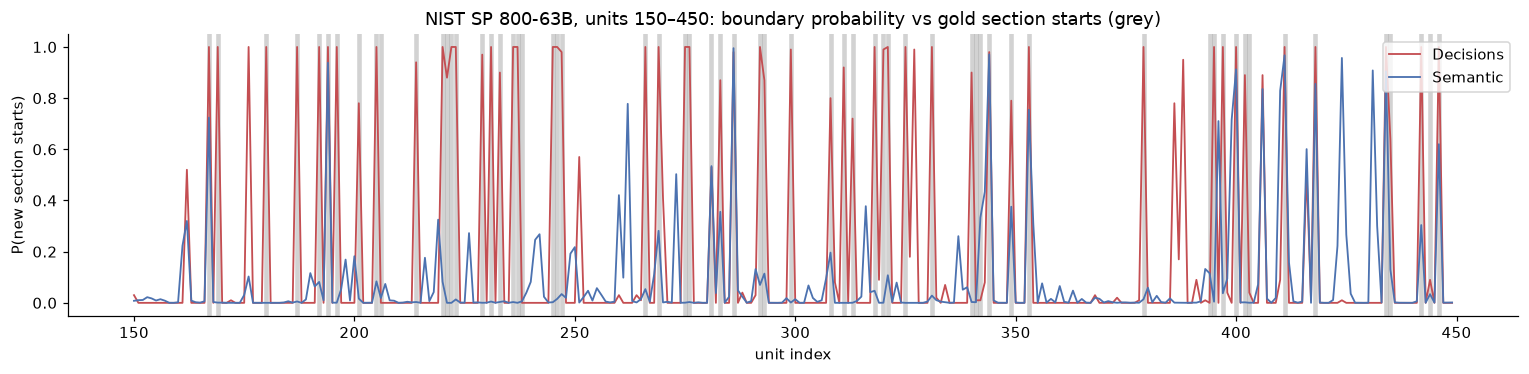

In [10]:
d = corpus["nist-sp-800-63b"]
lo, hi = 150, 450
ustarts = np.array([a for a, _ in d["units"]])
gold_units = [i for i in range(lo, hi) if ((d["gold"] >= ustarts[i]) & (d["gold"] < ustarts[i] + 120)).any()]
fig, ax = plt.subplots(figsize=(14, 3.5))
for g in gold_units:
    ax.axvline(g, color="grey", alpha=0.35, lw=3)
for name, color in [("Decisions + DP", "#C44E52"), ("Semantic + DP", "#4C72B0")]:
    ax.plot(range(lo, hi), d["scores"][name][lo:hi], color=color, lw=1.2, label=name.split(" +")[0])
ax.set_xlabel("unit index"); ax.set_ylabel("P(new section starts)"); ax.legend(loc="upper right")
ax.set_title("NIST SP 800-63B, units 150–450: boundary probability vs gold section starts (grey)")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "boundary_scores_example.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Build all chunkings
**What it does.** Applies the five chunkers to every document: the two baselines directly, and the shared DP
segmenter once per boundary scorer. **Why.** Section 5 scores these spans. **What to look for.** Chunk counts and
sizes per method. Decisions + DP makes the most chunks (1,487, median 286 tokens), and 2.3% of them are under 50
tokens; fixed windows are 400 tokens except the last one in each document.

In [11]:
METHODS = ["Fixed tokens", "Recursive", "Headings + DP", "Semantic + DP", "Decisions + DP"]
for d in corpus.values():
    d["chunks"] = {"Fixed tokens": fixed_chunks(d), "Recursive": recursive_chunks(d)}
    for name, p in d["scores"].items():
        d["chunks"][name] = segment(d["units"], p, d["text"])

sizes = pd.DataFrame([{"method": m, "doc": fid, "tokens": ntok(d["text"][a:b])}
                      for fid, d in corpus.items() for m in METHODS for a, b in d["chunks"][m]])
size_stats = sizes.groupby("method").tokens.agg(chunks="count", mean="mean", median="median",
                                                p10=lambda s: s.quantile(0.1), p90=lambda s: s.quantile(0.9),
                                                pct_under_50=lambda s: (s < 50).mean()).reindex(METHODS)
size_stats.style.format({"mean": "{:.0f}", "median": "{:.0f}", "p10": "{:.0f}", "p90": "{:.0f}", "pct_under_50": "{:.1%}"})

,chunks,mean,median,p10,p90,pct_under_50
method,,,,,,
Fixed tokens,1104,400,400,400,400,0.0%
Recursive,1120,345,364,285,396,0.0%
Headings + DP,1398,276,288,138,378,0.0%
Semantic + DP,1318,293,311,165,381,0.3%
Decisions + DP,1487,260,286,110,376,2.3%


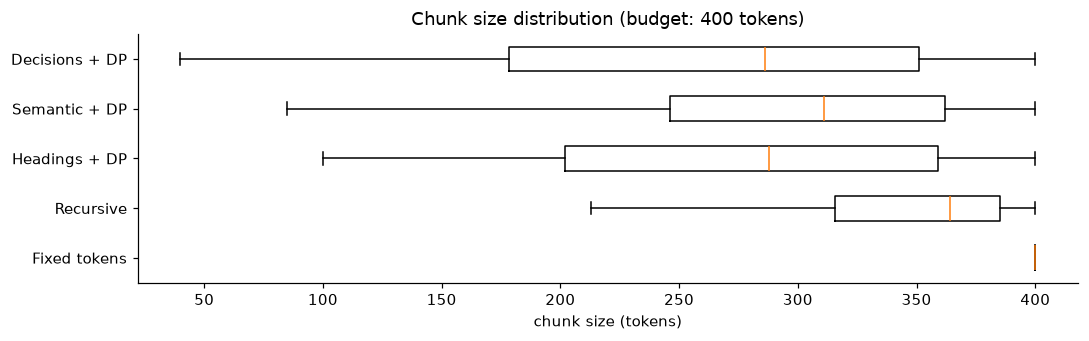

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.boxplot([sizes[sizes.method == m].tokens for m in METHODS], orientation="horizontal", showfliers=False)
ax.set_yticklabels(METHODS); ax.set_xlabel("chunk size (tokens)"); ax.set_title("Chunk size distribution (budget: 400 tokens)")
plt.tight_layout(); plt.show()

## 5. Evaluation
### 5.1 Boundary detection: can each scorer find the real section starts?
This scores each candidate unit as a binary *section-start* classifier against the gold outline, using the
four documents with an outline. We report average precision (AP) and ROC-AUC. It isolates boundary quality
from chunk packing.

In [13]:
GOLD_DOCS = [fid for fid, d in corpus.items() if len(d["gold"]) >= 10]
rows = []
for fid in GOLD_DOCS:
    d = corpus[fid]
    ustarts = np.array([a for a, _ in d["units"]])
    y = np.array([((d["gold"] >= s) & (d["gold"] < s + 120)).any() for s in ustarts])[1:]
    for name, p in d["scores"].items():
        rows.append({"doc": fid, "scorer": name.split(" +")[0], "AP": average_precision_score(y, p[1:]),
                     "ROC-AUC": roc_auc_score(y, p[1:]), "positives": y.sum(), "candidates": len(y)})
bd = pd.DataFrame(rows)
bd.pivot(index="doc", columns="scorer", values="AP").style.format("{:.2f}").background_gradient(cmap="Greens", axis=1).set_caption("Average precision of section-start detection (higher is better)")

scorer,Decisions,Headings,Semantic
doc,,,
arxiv-attention,0.64,0.59,0.22
irs-1040-instructions-2024,0.58,0.19,0.24
nist-sp-800-63b,0.64,0.36,0.31
rfc9110-http-semantics,0.54,0.58,0.50


In [14]:
bd.groupby("scorer")[["AP", "ROC-AUC"]].mean().style.format("{:.3f}").set_caption("Mean over the 4 outlined documents")

,AP,ROC-AUC
scorer,,
Decisions,0.598,0.883
Headings,0.431,0.822
Semantic,0.317,0.727


### 5.2 Do chunks respect sections?
* **Section-start recall @±200 chars**: share of gold section starts with a chunk boundary within 200
  characters;
* **Mixed-section chunks**: share of chunks with a gold section start more than 200 characters inside them,
  i.e. chunks that glue two sections together.

In [15]:
def boundary_metrics(chunks, gold, tol=200):
    starts = np.array([a for a, _ in chunks])
    recall = np.mean([np.abs(starts - g).min() <= tol for g in gold])
    mixed = np.mean([((gold > a + tol) & (gold < b - tol)).any() for a, b in chunks])
    return recall, mixed


rows = []
for fid in GOLD_DOCS:
    for m in METHODS:
        r, mx = boundary_metrics(corpus[fid]["chunks"][m], corpus[fid]["gold"])
        rows.append({"doc": fid, "method": m, "section-start recall": r, "mixed-section chunks": mx})
sec = pd.DataFrame(rows).groupby("method")[["section-start recall", "mixed-section chunks"]].mean().reindex(METHODS)
sec.style.format("{:.1%}").background_gradient(subset=["section-start recall"], cmap="Greens").background_gradient(subset=["mixed-section chunks"], cmap="Reds")

,section-start recall,mixed-section chunks
method,,
Fixed tokens,28.4%,46.3%
Recursive,34.0%,37.6%
Headings + DP,79.8%,8.9%
Semantic + DP,52.2%,23.7%
Decisions + DP,84.7%,8.0%


### 5.3 Retrieval: does the chunking help find the evidence?
For each method we embed every chunk of all six documents into **one pooled index**. Each benchmark question
then retrieves from it. A hit means a retrieved chunk covers ≥ 50% of that question's evidence quote. We also
report **evidence intact**: the share of evidence quotes that sit entirely inside a single chunk (i.e. the
chunker did not cut through the answer).

In [16]:
def retrieval_eval(method, ks=(1, 3, 5)):
    index = [(fid, a, b) for fid, d in corpus.items() for a, b in d["chunks"][method]]
    C = embed([corpus[fid]["text"][a:b] for fid, a, b in index])
    Q = embed(evidence.question.tolist())
    order = np.argsort(-(Q @ C.T), axis=1)
    hits, intact = [], []
    for qi, e in enumerate(evidence.itertuples()):
        s, t = e.span
        cover = np.array([fid == e.doc and max(0, min(b, t) - max(a, s)) / (t - s) >= 0.5 for fid, a, b in index])
        rank = np.flatnonzero(cover[order[qi]])
        hits.append(rank[0] + 1 if len(rank) else np.inf)
        intact.append(any(fid == e.doc and a <= s and t <= b for fid, a, b in index))
    hits = np.array(hits)
    return {"method": method, **{f"recall@{k}": (hits <= k).mean() for k in ks}, "MRR": np.mean(1 / hits),
            "evidence intact": np.mean(intact), "_hits": hits}


ret = pd.DataFrame([retrieval_eval(m) for m in METHODS]).set_index("method")
ret.drop(columns="_hits").style.format("{:.3f}").background_gradient(cmap="Greens")

,recall@1,recall@3,recall@5,MRR,evidence intact
method,,,,,
Fixed tokens,0.333,0.606,0.758,0.499,1.000
Recursive,0.364,0.636,0.758,0.533,0.939
Headings + DP,0.424,0.636,0.788,0.563,0.939
Semantic + DP,0.485,0.758,0.788,0.611,1.000
Decisions + DP,0.394,0.667,0.758,0.559,0.939


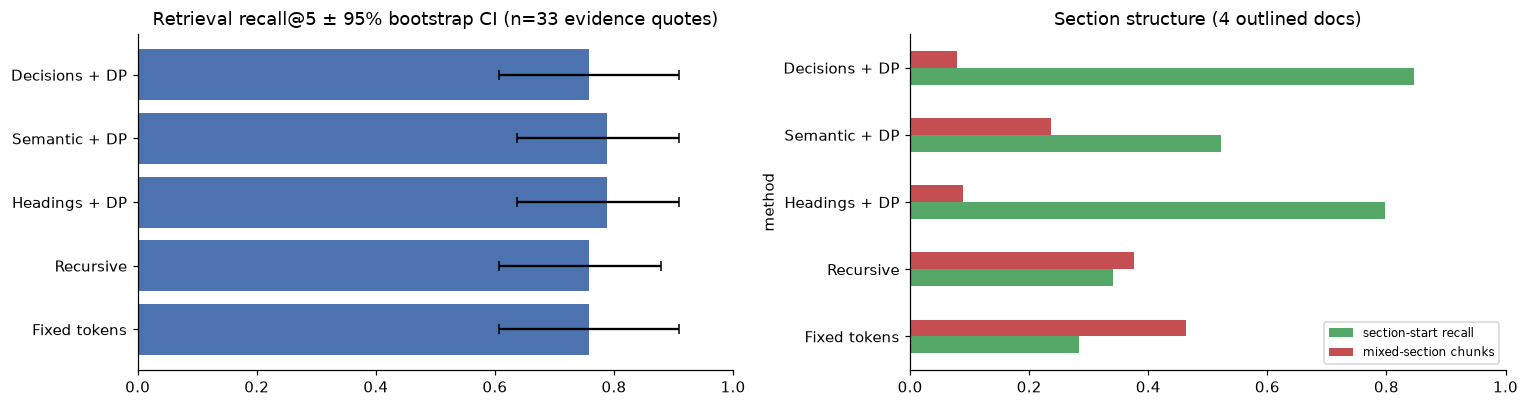

In [17]:
rng = np.random.default_rng(0)
boot = {m: [(ret.loc[m, "_hits"][rng.integers(0, len(evidence), len(evidence))] <= 5).mean() for _ in range(2000)] for m in METHODS}
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
lo_hi = np.array([np.percentile(boot[m], [2.5, 97.5]) for m in METHODS])
axes[0].barh(METHODS, ret["recall@5"], xerr=[ret["recall@5"] - lo_hi[:, 0], lo_hi[:, 1] - ret["recall@5"]], color="#4C72B0", capsize=3)
axes[0].set_xlim(0, 1); axes[0].set_title(f"Retrieval recall@5 ± 95% bootstrap CI (n={len(evidence)} evidence quotes)")
sec.plot.barh(ax=axes[1], color=["#55A868", "#C44E52"]); axes[1].set_xlim(0, 1); axes[1].set_title("Section structure (4 outlined docs)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.4 One example, five chunkings
Take one benchmark question with evidence in the middle of the NIST standard. For each method, show where
the chunk holding the evidence starts and ends. Structure-aware chunks should open on a section heading.

In [18]:
e = evidence[evidence.qid == "bm-036"].iloc[0]
d = corpus[e.doc]
print("Q:", e.question, "\nEvidence:", e.quote[:150].replace("\n", " "), "…\n")
for m in METHODS:
    a, b = next((a, b) for a, b in d["chunks"][m] if a <= e.span[0] < b)
    chunk = d["text"][a:b].replace("\n\n", " ¶ ")
    print(f"── {m}: {ntok(d['text'][a:b])} tokens, evidence starts at token {ntok(d['text'][a:e.span[0]])}")
    print(f"   starts: {chunk[:150]!r}\n   ends:   {chunk[-110:]!r}\n")

Q: Per NIST SP 800-63B, what is the minimum length of a memorized secret chosen by the subscriber? 
Evidence: Memorized secrets SHALL be at least 8 characters in length if chosen by the subscriber. …

── Fixed tokens: 400 tokens, evidence starts at token 193
   starts: '63b ¶ 5 Authenticator and Verifier Requirements ¶ This section is normative. ¶ This section provides the detailed requirements specific to each type o'
   ends:   's. Unicode [ISO/ISC 10646] characters SHOULD be accepted as well. To make allowances for likely mistyping, ver'

── Recursive: 337 tokens, evidence starts at token 217
   starts: 'This publication is available free of charge from: https://doi.org/10.6028/NIST.SP.800-63b ¶ 5 Authenticator and Verifier Requirements ¶ This section '
   ends:   'ale for this is presented in Appendix A Strength of Memorized Secrets. ¶ 5.1.1.2 Memorized Secret Verifiers ¶ '

── Headings + DP: 120 tokens, evidence starts at token 13
   starts: '5.1.1.1 Memorized Secret Authenticator

In [19]:
spent = sum(v["usage"]["cost"] for v in decision_cache.data.values() if "usage" in v)
print(f"Total Decisions API spend recorded in cache: ${spent:.2f} over {len(decision_cache.data)} calls")

Total Decisions API spend recorded in cache: $0.14 over 144 calls


## 6. Takeaways
1. **The Decisions API is the best boundary detector here.** Treated as a section-start classifier on the 4
   outlined documents, it scores **mean AP 0.60 / ROC-AUC 0.88**. The heading heuristic scores 0.43 / 0.82 and
   embedding distance 0.32 / 0.73. The gap is widest where the typography is messy: on the IRS 1040
   instructions it scores AP 0.58 vs 0.19 for headings. Headings stay competitive on cleanly numbered documents
   (the RFC and the arXiv paper).
2. **Its chunks respect document structure.** With the same DP and the same 400-token budget, Decisions + DP
   puts a boundary within ±200 chars of **85%** of real section starts, and only **8%** of its chunks mix two
   sections. The others: fixed windows 28% / 46%, recursive 34% / 38%, semantic + DP 52% / 24%, headings + DP
   80% / 9%.
3. **It is cheap.** 144 calls over about 386k document tokens cost **\$0.14**, roughly **\$0.37 per 1M document
   tokens**. One call scores 32 candidate boundaries against one shared 40-passage state, which is billed once.
4. **Retrieval differences are not significant.** Recall@5 is 0.76–0.79 for every method, and with only 33
   evidence quotes the bootstrap CIs overlap heavily. The leader on recall@1/MRR flips between runs: semantic +
   DP leads with the free embeddings (0.49 / 0.61), and Decisions + DP led with the paid ones. On this data, structure-aware chunking mainly buys **clean, self-contained, citable chunks**
   (see 5.4), not retrieval recall. A larger question set would be needed to settle the retrieval question.
5. **Trade-offs.** Its chunks run a little smaller (median 286 tokens vs 364 for recursive), and 2% are under 50
   tokens. Raise `MIN_CHUNK` or `small_penalty` if that matters. Fixed windows keep 100% of evidence intact,
   but only because of their 50-token overlap.
6. **Recipe worth keeping:** extraction blocks as candidates → windowed `noul` boundary probabilities → DP under
   a token budget. The same probabilities can also build a hierarchy: very high p = section, middling p = a
   sub-chunk break.